In [1]:
import pathlib
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

import statsmodels.api as sm
from statsmodels.formula.api import mixedlm, ols
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

plt.rcParams['pdf.fonttype']=42

%load_ext autoreload
%autoreload 2 


%matplotlib inline

In [2]:
basedir = pathlib.Path("/media/mplitt/SSD_storage/2P_scratch/R27F02LexA_jGCaMP8s_Ti{RFP}Ti_OctAlpha2R")

sess_df = pd.read_csv(basedir / 'sessions.csv')
print(sess_df.columns)
sess_df['fly_id'] = [row['date']+'_'+row['fly'] +'_' + row['condition'] for _, row in sess_df.iterrows()]

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/OctAlpha2R_KO/')
figfolder.mkdir(parents=True, exist_ok=True)

sess_df = sess_df.loc[sess_df['usable']==1]




Index(['date', 'fly', 'sess', 'fictrac_scan_num', 'fictrac_file', 'condition',
       'scan_type', 'closed_loop', 'dark', 'usable', 'notes'],
      dtype='str')


In [3]:
sess_df.head()

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,closed_loop,dark,usable,notes,fly_id
0,05_05_2026,fly1,closed_loop-000,0,fictrac-20260505_102519.dat,nocrispr_control,closed_loop,1,0,1,NaN,05_05_2026_fly1_nocrispr_control
1,05_05_2026,fly1,dark-001,1,fictrac-20260505_102519.dat,nocrispr_control,dark,0,1,1,NaN,05_05_2026_fly1_nocrispr_control
2,05_05_2026,fly2,closed_loop-000,0,fictrac-20260505_115036.dat,nocrispr_control,closed_loop,1,0,1,NaN,05_05_2026_fly2_nocrispr_control
3,05_05_2026,fly2,dark-001,1,fictrac-20260505_115036.dat,nocrispr_control,dark,0,1,1,NaN,05_05_2026_fly2_nocrispr_control
4,06_05_2026,fly1,closed_loop-000,0,fictrac-20260506_110733.dat,nocrispr_control,closed_loop,1,0,1,NaN,06_05_2026_fly1_nocrispr_control


In [4]:
def load_row(row):
    outdir = pathlib.PurePath( basedir / row['condition'] / row['date'] / row['fly'] / row['sess'] / 'preprocess.pkl')
    return st2p.preprocessing.EBImagingSession.from_file(outdir)

In [5]:
stats_df = nmp.oa_receptor_ko.offset_stats(sess_df, load_row)
stats_df.head()

,fly_id,cl,dark,condition,offset_var,offset_mean,offset_mag
0,05_05_2026_fly1_nocrispr_control,1,0,nocrispr_control,0.405806,2.487676,0.594194
1,05_05_2026_fly1_nocrispr_control,0,1,nocrispr_control,0.827891,2.452659,0.172109
2,05_05_2026_fly2_nocrispr_control,1,0,nocrispr_control,0.349589,-1.809870,0.650411
3,05_05_2026_fly2_nocrispr_control,0,1,nocrispr_control,0.797794,1.271879,0.202206
4,06_05_2026_fly1_nocrispr_control,1,0,nocrispr_control,0.607541,-0.899074,0.392459


In [6]:
stats_df_unique = nmp.oa_receptor_ko.offset_stats_unique(stats_df)
stats_df_unique.head()

,fly_id,cl,condition,dark,offset_var,offset_var_logit,offset_mean,offset_mag
0,05_05_2026_fly1_nocrispr_control,1,nocrispr_control,0,0.405806,-0.381332,2.487676,0.594194
1,05_05_2026_fly1_nocrispr_control,0,nocrispr_control,1,0.827891,1.570756,2.452659,0.172109
2,05_05_2026_fly2_nocrispr_control,1,nocrispr_control,0,0.349589,-0.620847,4.473316,0.650411
3,05_05_2026_fly2_nocrispr_control,0,nocrispr_control,1,0.797794,1.372563,1.271879,0.202206
4,06_05_2026_fly1_nocrispr_control,1,nocrispr_control,0,0.607541,0.436986,5.384111,0.392459


In [7]:
stats_df_plot = nmp.oa_receptor_ko.offset_stats_plot(stats_df_unique)

12 12


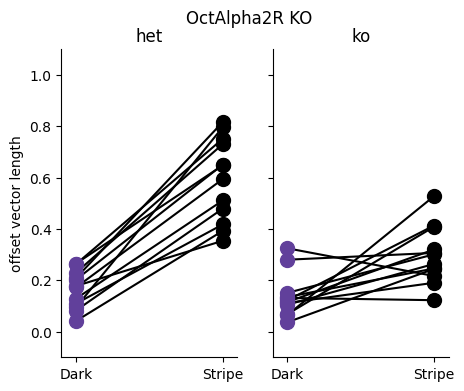

In [8]:
fig,ax = plt.subplots(1,2,sharey=True, figsize=[5,4])

c_df = stats_df_plot.loc[stats_df_plot['condition']=='nocrispr_control']
ax[0].set_title('het')

ax[0].plot([0,1], c_df[['offset_mag_dark', 'offset_mag_closed_loop']].T, color='black', zorder=-1)
ax[0].scatter(np.zeros((c_df.shape[0],)), c_df['offset_mag_dark'], color=plt.cm.Purples(.8), alpha=1, s=100)
ax[0].scatter(np.ones((c_df.shape[0],)), c_df['offset_mag_closed_loop'], color='black', alpha=1, s=100)

ko_df = stats_df_plot.loc[stats_df_plot['condition']=='ko']
ax[1].set_title('ko')

ax[1].plot([0,1], ko_df[['offset_mag_dark', 'offset_mag_closed_loop']].T, color='black', zorder=-1)
ax[1].scatter(np.zeros((ko_df.shape[0],)), ko_df['offset_mag_dark'], color=plt.cm.Purples(.8), alpha=1, s=100)
ax[1].scatter(np.ones((ko_df.shape[0],)), ko_df['offset_mag_closed_loop'], color='black', alpha=1, s=100)



for _ax in ax:
    _ax.set_ylim([-0.1,1.1])
    _ax.set_xlim([-.1,1.1])
    _ax.set_yticks([0,.2,.4,.6,.8,1.])

    _ax.set_xticks([0, 1], labels=['Dark', 'Stripe'])
    _ax.spines['top'].set_visible(False)
    _ax.spines['right'].set_visible(False)
    
ax[0].set_ylabel('offset vector length')
fig.suptitle('OctAlpha2R KO')
print(ko_df.shape[0], c_df.shape[0])

fig.savefig(figfolder / 'offset_mag_summary.pdf', format='pdf')


In [9]:
import pingouin as pg
from pingouin import mixed_anova, pairwise_tests
aov = mixed_anova(dv='offset_var_logit', between='condition',
                  within='dark', subject='fly_id', data=stats_df_unique)
aov

,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,condition,7.675698,1,22,7.675698,15.567531,6.886689e-04,0.414388,NaN
1,dark,31.717615,1,22,31.717615,87.157866,4.151934e-09,0.798457,1.0
2,Interaction,3.582269,1,22,3.582269,9.843834,4.786057e-03,0.309128,NaN


<Axes: xlabel='Theoretical quantiles', ylabel='Ordered quantiles'>

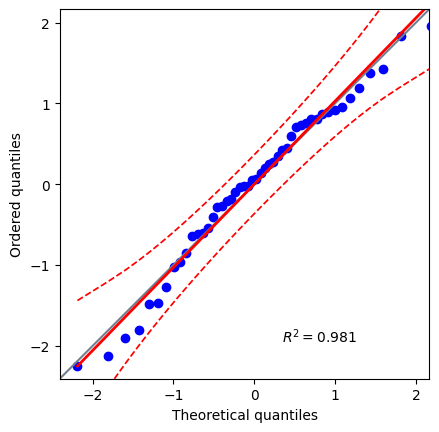

In [10]:
pg.qqplot(stats_df_unique['offset_var_logit'])


In [11]:
tt = pairwise_tests(dv='offset_var_logit', between='condition',
                   subject='fly_id', within='dark', data=stats_df_unique,
                   padjust='holm', parametric=True, interaction=True, within_first=False)

print(tt['Contrast'].unique())
tt

['condition' 'dark' 'condition * dark']


,Contrast,condition,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,condition,-,ko,nocrispr_control,False,True,3.945571,22.0,two-sided,6.886689e-04,NaN,NaN,41.147,1.555229
1,dark,-,0,1,True,True,-7.934225,23.0,two-sided,4.940409e-08,NaN,NaN,2.897e+05,-1.976494
2,condition * dark,ko,0,1,True,True,-3.733459,11.0,two-sided,3.303531e-03,3.303531e-03,holm,14.703,-1.660387
3,condition * dark,nocrispr_control,0,1,True,True,-11.184784,11.0,two-sided,2.389139e-07,4.778278e-07,holm,5.953e+04,-3.082197


In [12]:
tt = pairwise_tests(dv='offset_var_logit', between='condition',
                   subject='fly_id', within='dark', data=stats_df_unique,
                   padjust='holm', parametric=True, interaction=True, within_first=True, correction=False)

print(tt['Contrast'].unique())
tt

['dark' 'condition' 'dark * condition']


,Contrast,dark,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,dark,-,0,1,True,True,-7.934225,23.0,two-sided,4.940409e-08,NaN,NaN,2.897e+05,-1.976494
1,condition,-,ko,nocrispr_control,False,True,3.945571,22.0,two-sided,6.886689e-04,NaN,NaN,41.147,1.555229
2,dark * condition,0,ko,nocrispr_control,False,True,5.154023,22.0,two-sided,3.631166e-05,0.000073,holm,481.615,2.031565
3,dark * condition,1,ko,nocrispr_control,False,True,0.927709,22.0,two-sided,3.636254e-01,0.363625,holm,0.51,0.365676


In [13]:
dh_bins = np.linspace(.0, 3.14, num=20)

stats_df = nmp.oa_receptor_ko.rho_stats(sess_df, load_row, dh_bins=dh_bins)

# stats_df = stats_df.loc[stats_df['cl']!=1] # exclude first closed loop session
# stats_df.loc[stats_df['cl']>1, 'cl'] = 1 #
# stats_df.loc[stats_df['dark']>=1, 'dark'] = 1 # 

grouped = stats_df.groupby(['fly_id','dark','condition'])['rho_dig'].apply(lambda x: np.nanmean(np.stack(x),axis=0))
grouped = grouped.reset_index()

grouped.head()

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/oa_receptor_ko.py:225: RuntimeWarning: Mean of empty slice
  rho_dig = np.array([ts.rho[dh_dig == i].mean() for i in range(len(dh_bins))])
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/oa_receptor_ko.py:225: RuntimeWarning: Mean of empty slice
  rho_dig = np.array([ts.rho[dh_dig == i].mean() for i in range(len(dh_bins))])
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plastici

,fly_id,dark,condition,rho_dig
0,05_05_2026_fly1_ko,0,ko,"[0.3100996485845376, 0.39045840089724765, 0.38..."
1,05_05_2026_fly1_ko,1,ko,"[0.278569294557517, 0.32133330233984, 0.335299..."
2,05_05_2026_fly1_nocrispr_control,0,nocrispr_control,"[0.33258610477366707, 0.35034798014731267, 0.3..."
3,05_05_2026_fly1_nocrispr_control,1,nocrispr_control,"[0.2004146600834552, 0.23506099983460718, 0.24..."
4,05_05_2026_fly2_ko,0,ko,"[0.2835041900530156, 0.2992823553305658, 0.309..."


/media/mplitt/SSD_storage/fig_scratch/OctAlpha2R_KO


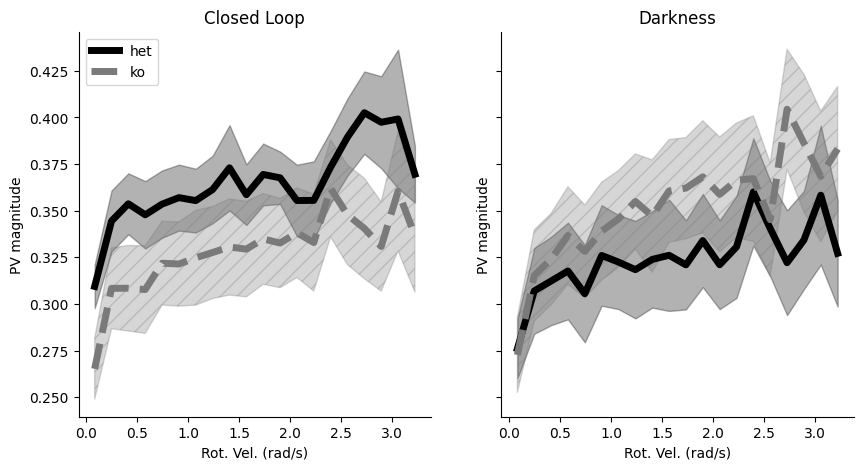

In [15]:
dh_bin_centers = dh_bins+np.diff(dh_bins)[0]/2
conditions = ('nocrispr_control','ko') 
rho_dict = {}
for cond in conditions:
    rho_dict[cond] = {'dark_rho':[],
                      'cl_rho':[]}

for fly in grouped['fly_id'].unique():
    if (grouped['fly_id']==fly).sum()>1:
        
        cond = grouped.loc[grouped['fly_id']==fly,'condition'].iloc[0]
        
        dark_rho = grouped.loc[(grouped['fly_id']==fly) * (grouped['dark']==1), 'rho_dig']
        cl_rho = grouped.loc[(grouped['fly_id']==fly) * (grouped['dark']==0), 'rho_dig']
        
        
        rho_dict[cond]['dark_rho'].append(dark_rho.iloc[0])
        rho_dict[cond]['cl_rho'].append(cl_rho.iloc[0])

for cond in conditions:
    
        rho_dict[cond]['dark_rho'] = np.stack(rho_dict[cond]['dark_rho'])
        rho_dict[cond]['cl_rho'] = np.stack(rho_dict[cond]['cl_rho'])


fig, ax= plt.subplots(1,2, figsize=[10,5], sharey=True)
mu,sem = np.nanmean(rho_dict['nocrispr_control']['cl_rho'],axis=0), sp.stats.sem(rho_dict['nocrispr_control']['cl_rho'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color='black', linewidth=5, label='het')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color='black', alpha=.3)


mu,sem = np.nanmean(rho_dict['ko']['cl_rho'],axis=0), sp.stats.sem(rho_dict['ko']['cl_rho'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color=plt.cm.Greys(.6), linewidth=5, label ='ko', linestyle='--')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color=plt.cm.Greys(.6), alpha=.3, hatch='//')


ax[0].legend()


mu,sem = np.nanmean(rho_dict['nocrispr_control']['dark_rho'],axis=0), sp.stats.sem(rho_dict['nocrispr_control']['dark_rho'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color='black', linewidth=5)
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color='black', alpha=.3)


mu,sem = np.nanmean(rho_dict['ko']['dark_rho'],axis=0), sp.stats.sem(rho_dict['ko']['dark_rho'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color=plt.cm.Greys(.6), linewidth=5, label ='ko', linestyle='--')
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color=plt.cm.Greys(.6), alpha=.3, hatch='//')





for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xlabel('Rot. Vel. (rad/s)')
    a.set_ylabel('PV magnitude')
ax[0].set_title('Closed Loop')
ax[1].set_title('Darkness')

print(figfolder)
fig.savefig(figfolder / 'PVMag_v_RotVel.pdf', format='pdf')
    

In [22]:
h,p = sp.stats.kruskal(np.nanmean(rho_dict['control']['cl_rho'],axis=-1), 
                       np.nanmean(rho_dict['vglut_rnai']['cl_rho'],axis=-1),
                            np.nanmean(rho_dict['rnai_67968']['cl_rho'], axis=-1))
print(h,p)

pvals = []
t,p = sp.stats.mannwhitneyu(np.nanmean(rho_dict['control']['cl_rho'],axis=-1), 
                            np.nanmean(rho_dict['rnai_67968']['cl_rho'], axis=-1))
print(t,p)
pvals.append(p)

t,p = sp.stats.mannwhitneyu(np.nanmean(rho_dict['vglut_rnai']['cl_rho'],axis=-1), 
                            np.nanmean(rho_dict['rnai_67968']['cl_rho'], axis=-1))
print(t,p)
pvals.append(p)

t,p = sp.stats.mannwhitneyu(np.nanmean(rho_dict['control']['cl_rho'],axis=-1), 
                            np.nanmean(rho_dict['vglut_rnai']['cl_rho'], axis=-1))
print(t,p)
pvals.append(p)

reject, pval_corr = pg.multicomp(pvals, method='holm')
print(reject, pval_corr)

8.055888429752073 0.017810907741920838
90.0 0.015123134403066842
97.0 0.018081721820705336
56.0 0.9719131339533064
[ True  True False] [0.0453694  0.0453694  0.97191313]


In [23]:
dh_bins = np.linspace(-2, 2, num=20)
stats_df = nmp.tbh_rnai.dphi_stats(sess_df, load_row, dh_bins)


stats_df = stats_df.loc[stats_df['cl']!=1] # exclude first closed loop session
stats_df.loc[stats_df['cl']>1, 'cl'] = 1 #
stats_df.loc[stats_df['dark']>=1, 'dark'] = 1 # 

grouped = stats_df.groupby(['fly_id','dark','rnai'])['dphi_dig'].apply(lambda x: np.nanmean(np.stack(x),axis=0))

grouped = grouped.reset_index()

control
vglut_rnai
rnai_67968


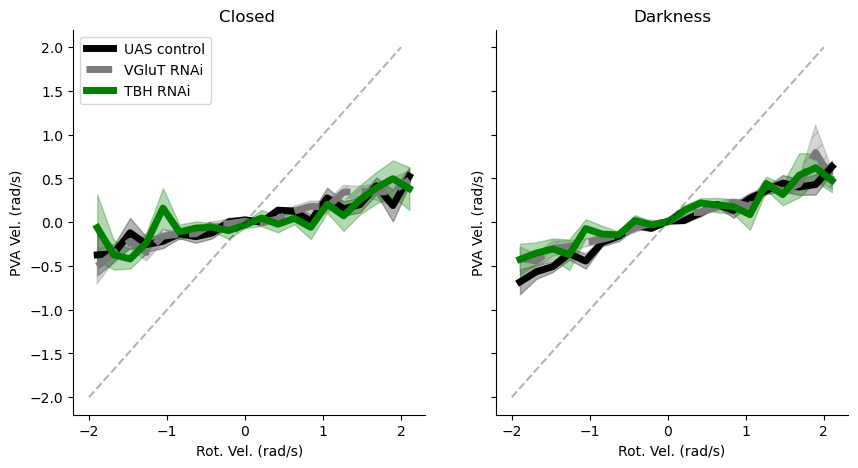

In [24]:
dh_bin_centers = dh_bins+np.diff(dh_bins)[0]/2
conditions = ('control','vglut_rnai', 'rnai_67968') 
dphi_dict = {}
for cond in conditions:
    dphi_dict[cond] = {'dark_dphi':[],
                      'cl_dphi':[]}

for fly in grouped['fly_id'].unique():
    if (grouped['fly_id']==fly).sum()>1:
        
        cond = grouped.loc[grouped['fly_id']==fly,'rnai'].iloc[0]
        
        dark_dphi = grouped.loc[(grouped['fly_id']==fly) * (grouped['dark']==1), 'dphi_dig']
        cl_dphi = grouped.loc[(grouped['fly_id']==fly) * (grouped['dark']==0), 'dphi_dig']
        
        dphi_dict[cond]['dark_dphi'].append(dark_dphi.iloc[0])
        dphi_dict[cond]['cl_dphi'].append(cl_dphi.iloc[0])
        
for cond in conditions:
    print(cond)
    dphi_dict[cond]['dark_dphi'] = np.stack(dphi_dict[cond]['dark_dphi'])
    dphi_dict[cond]['cl_dphi'] = np.stack(dphi_dict[cond]['cl_dphi'])


fig, ax= plt.subplots(1,2, figsize=[10,5], sharey=True)
mu,sem = np.nanmean(dphi_dict['control']['cl_dphi'],axis=0), sp.stats.sem(dphi_dict['control']['cl_dphi'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color='black', linewidth=5, label='UAS control')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color='black', alpha=.3)


mu,sem = np.nanmean(dphi_dict['vglut_rnai']['cl_dphi'],axis=0), sp.stats.sem(dphi_dict['vglut_rnai']['cl_dphi'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color=plt.cm.Greys(.6), linewidth=5, label='VGluT RNAi', linestyle='--')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color=plt.cm.Greys(.6), alpha=.3, hatch='//')


mu,sem = np.nanmean(dphi_dict['rnai_67968']['cl_dphi'],axis=0), sp.stats.sem(dphi_dict['rnai_67968']['cl_dphi'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color='green', linewidth=5, label='TBH RNAi')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color='green', alpha=.3)

ax[0].legend()

mu,sem = np.nanmean(dphi_dict['control']['dark_dphi'],axis=0), sp.stats.sem(dphi_dict['control']['dark_dphi'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color='black', linewidth=5)
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color='black', alpha=.3)


mu,sem = np.nanmean(dphi_dict['vglut_rnai']['dark_dphi'],axis=0), sp.stats.sem(dphi_dict['vglut_rnai']['dark_dphi'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color=plt.cm.Greys(.6), linewidth=5, label ='VGluT RNAi', linestyle='--')
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color=plt.cm.Greys(.6), alpha=.3, hatch='//')



mu,sem = np.nanmean(dphi_dict['rnai_67968']['dark_dphi'],axis=0), sp.stats.sem(dphi_dict['rnai_67968']['dark_dphi'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color='green', linewidth=5)
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color='green', alpha=.3)


for a in ax:
    
    a.plot([-2,2],[-2,2], 'k--', alpha=.3)
    # a.set_ylim([-1,1])
    # a.set_xlim([-1,1])
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xlabel('Rot. Vel. (rad/s)')
    a.set_ylabel('PVA Vel. (rad/s)')
    
ax[0].set_title('Closed ')
ax[1].set_title('Darkness')

fig.savefig(figfolder / 'dPVA_v_RotVel.pdf', format='pdf')
    

In [25]:
reg_df = nmp.tbh_rnai.reformat_dphi_stats_for_reg(grouped, dh_bins)

In [26]:
df = reg_df.loc[reg_df['dark']==0]
# model = mixedlm('dphi ~ C(rnai, Treatment("rnai_67968"))*dh', df, groups=df['fly_id'])
# model = ols('dphi ~ dh*C(rnai, Treatment("rnai_67968"))-C(rnai, Treatment("rnai_67968"))', df)
model = ols('dphi ~ dh*C(rnai, Treatment("rnai_67968"))', df)

result = model.fit()
print(result.summary())
print(result.pvalues)
hypotheses = '(dh:C(rnai, Treatment("rnai_67968"))[T.control] = 0), (dh:C(rnai, Treatment("rnai_67968"))[T.vglut_rnai] = 0)'
print(result.wald_test(hypotheses))
hypotheses = '(C(rnai, Treatment("rnai_67968"))[T.control] = 0), (C(rnai, Treatment("rnai_67968"))[T.vglut_rnai] = 0)'
print(result.wald_test(hypotheses))
# intxns = ['C(rnai, Treatment("rnai_67968"))[T.control]:dh',
#        'C(rnai, Treatment("rnai_67968"))[T.gal4_control]:dh']

# intxn_pvals = [result.pvalues[k] for k in intxns]
# print(multipletests(intxn_pvals , alpha=.05, method='holm'))

                            OLS Regression Results                            
Dep. Variable:                   dphi   R-squared:                       0.252
Model:                            OLS   Adj. R-squared:                  0.246
Method:                 Least Squares   F-statistic:                     42.73
Date:                Tue, 02 Sep 2025   Prob (F-statistic):           5.76e-38
Time:                        23:26:05   Log-Likelihood:                -305.47
No. Observations:                 640   AIC:                             622.9
Df Residuals:                     634   BIC:                             649.7
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                        coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------

/home/mplitt/mambaforge/envs/NeuroModPlasticity/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


/home/mplitt/repos/NeuromodPlasticity/NeuromodPlasticity/tbh_rnai.py:322: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=[8,4])


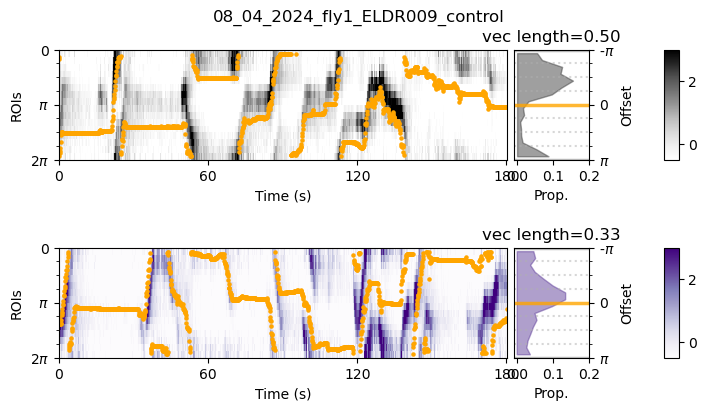

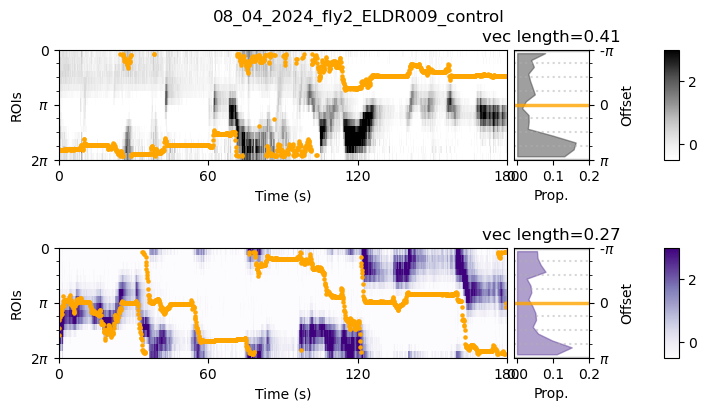

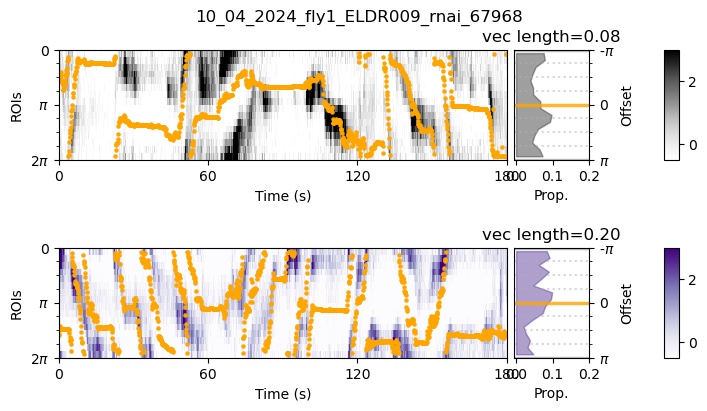

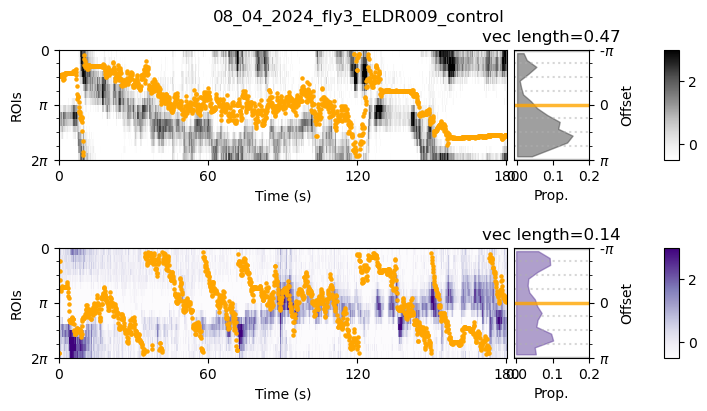

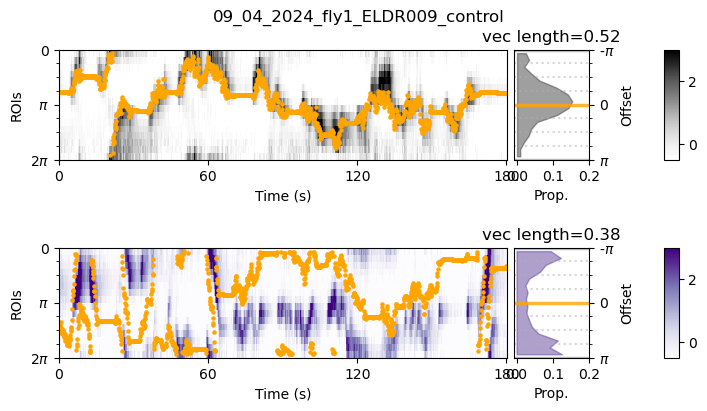

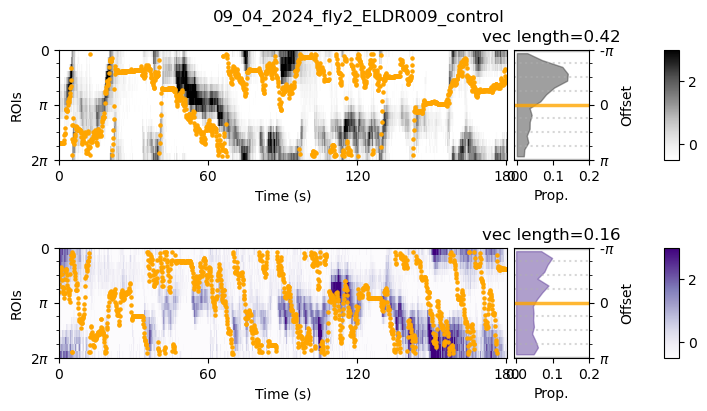

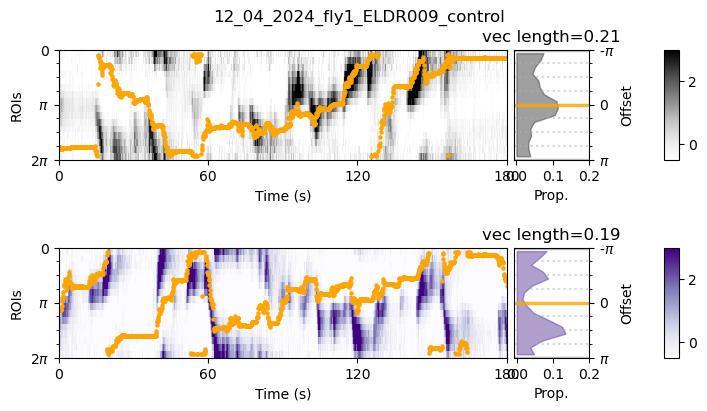

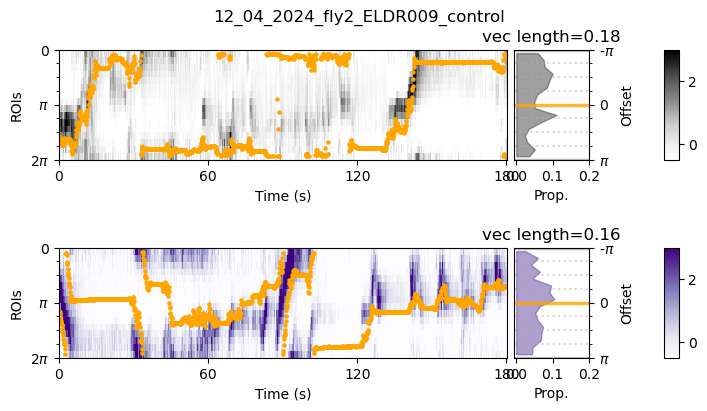

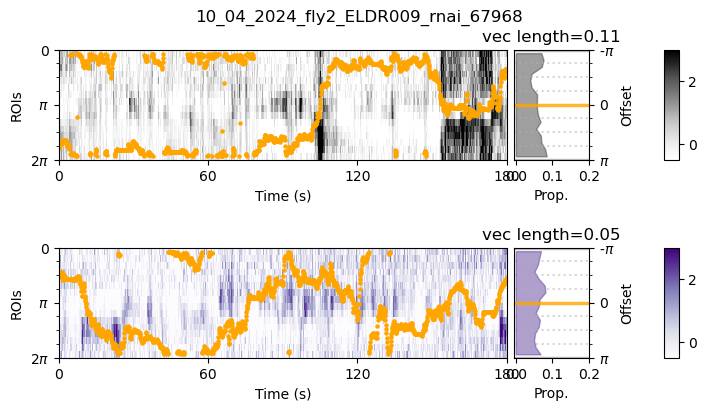

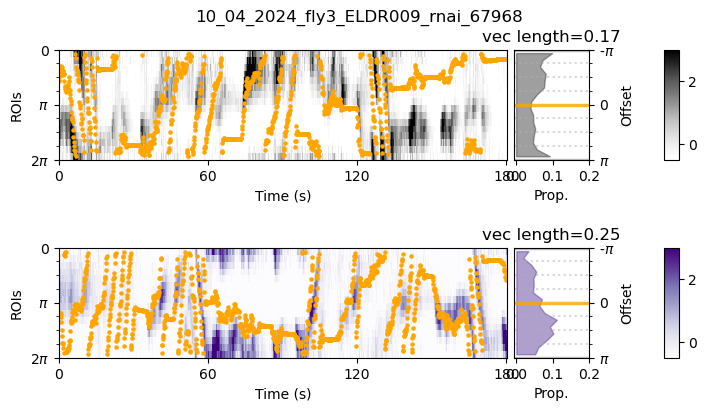

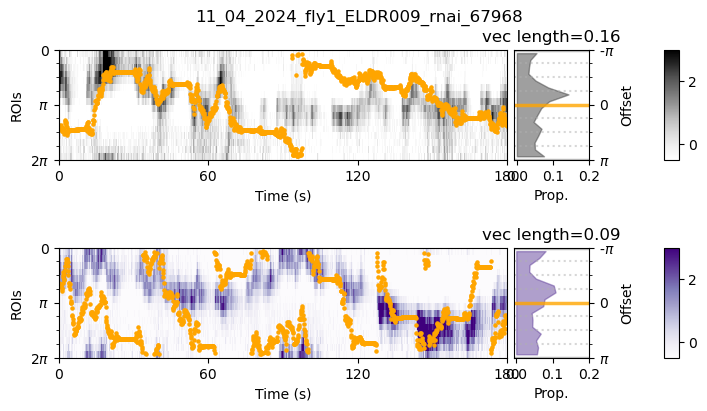

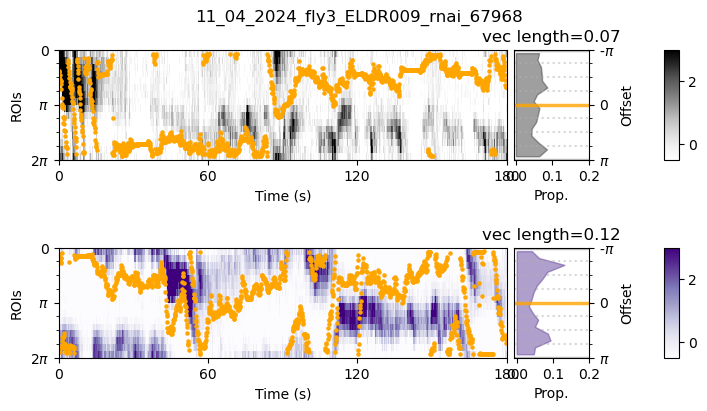

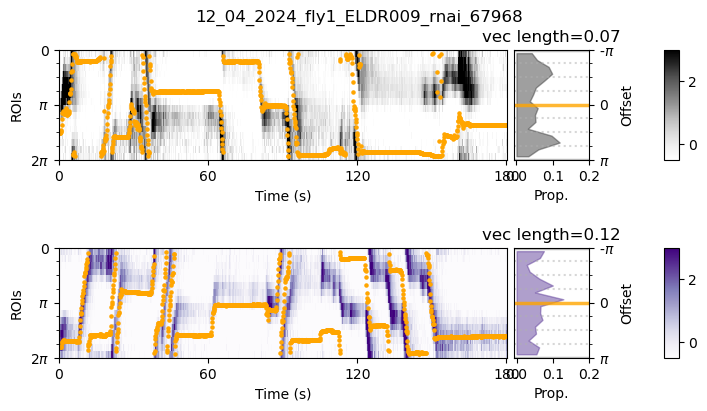

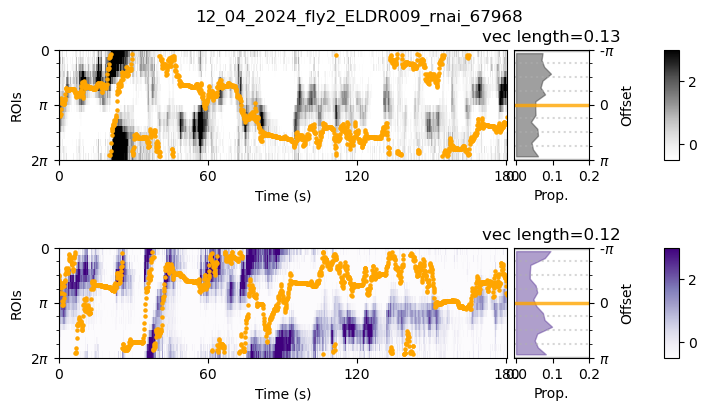

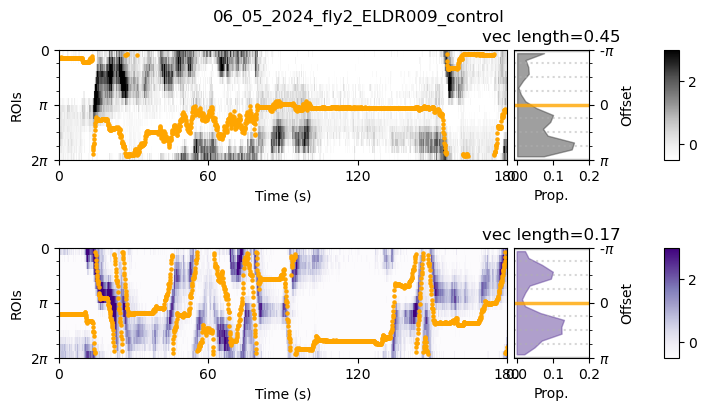

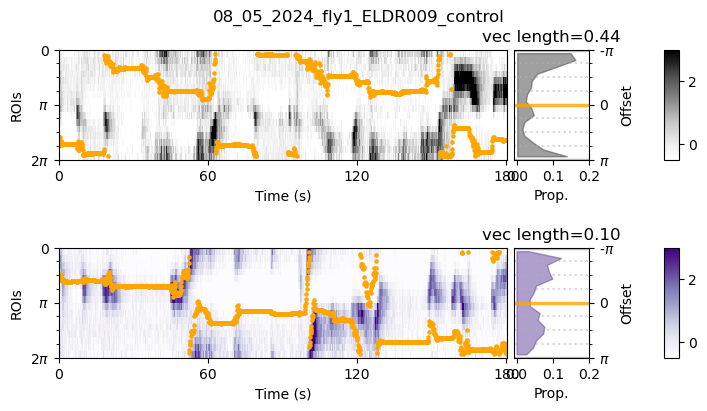

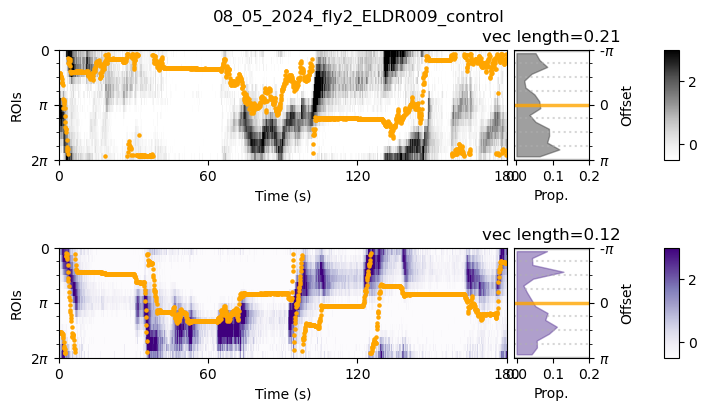

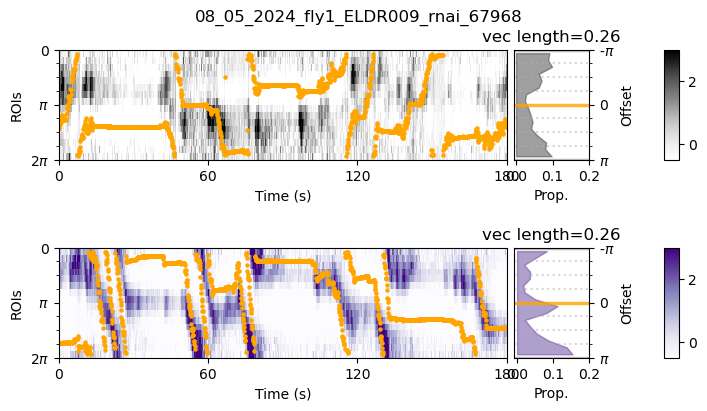

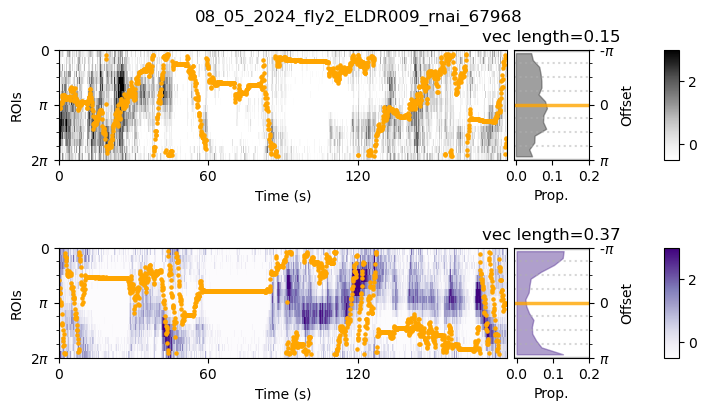

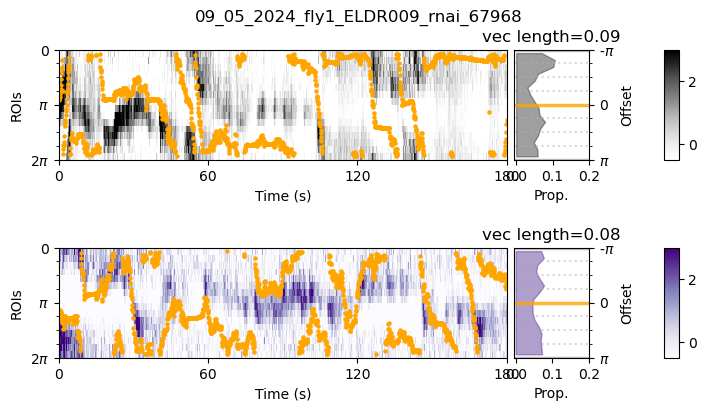

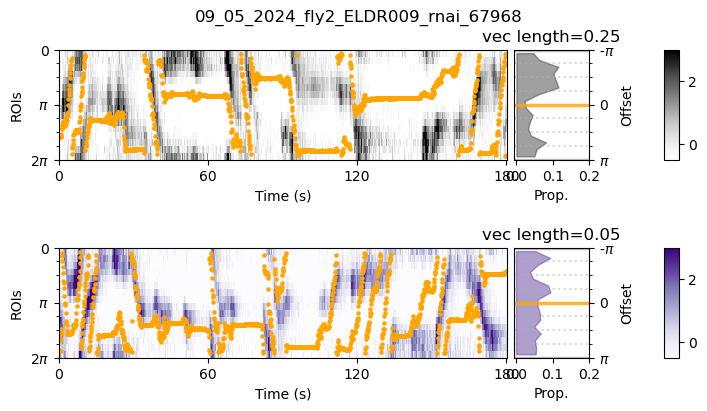

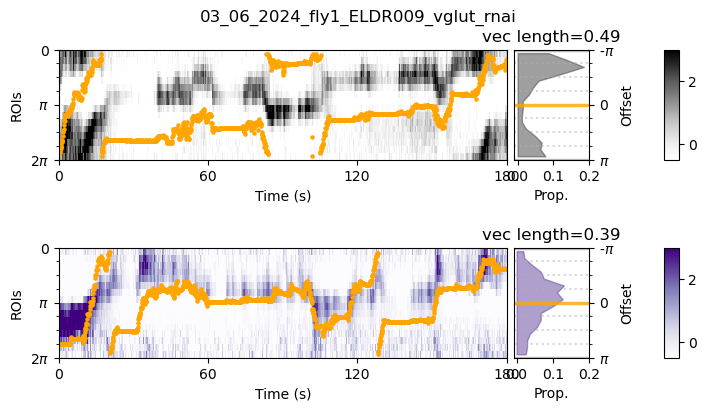

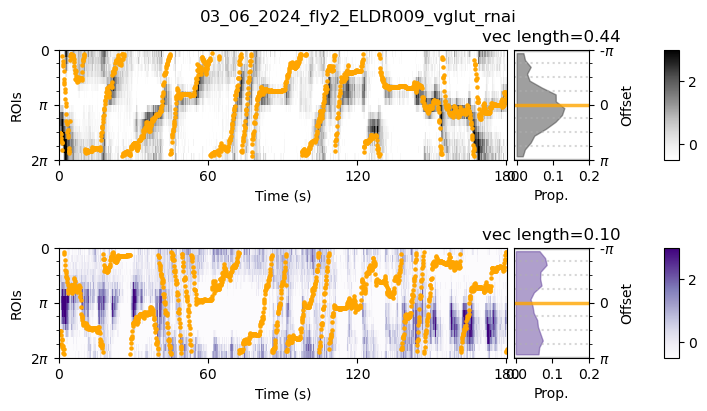

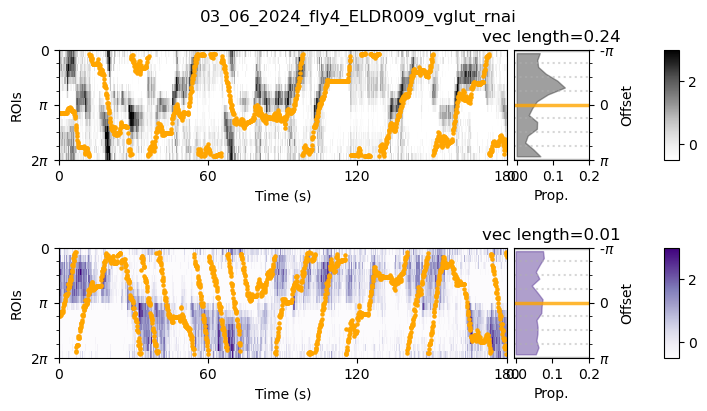

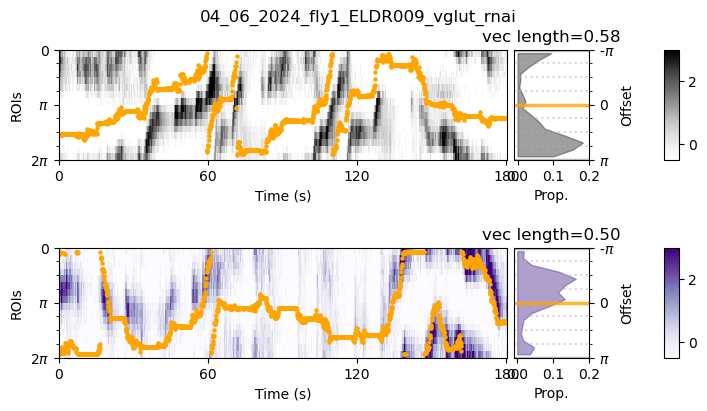

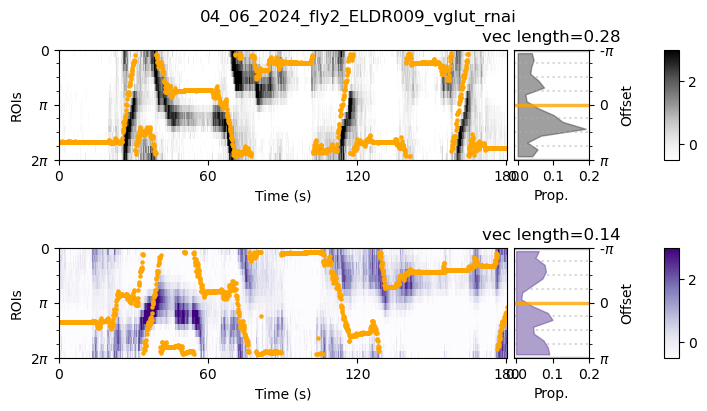

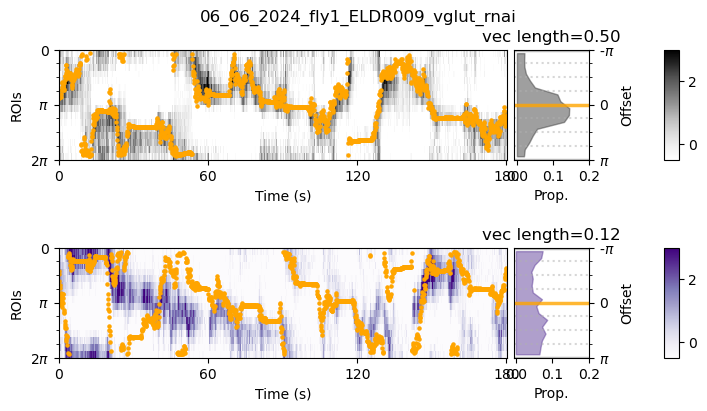

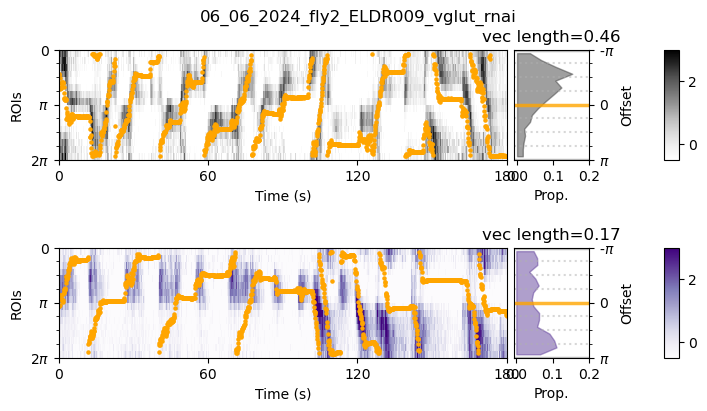

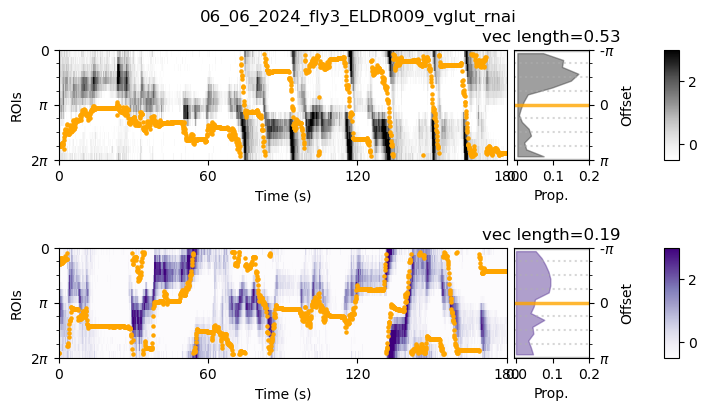

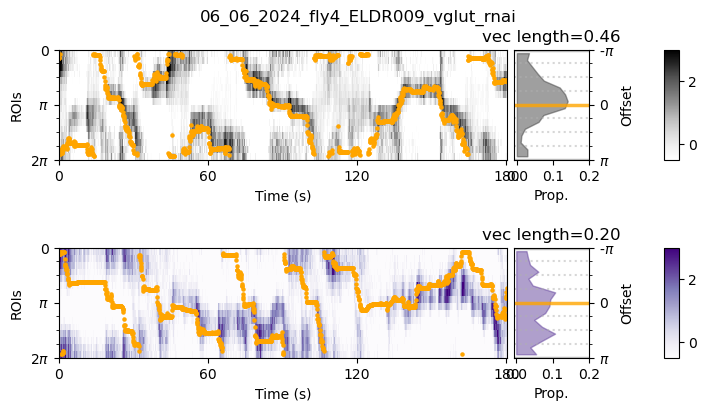

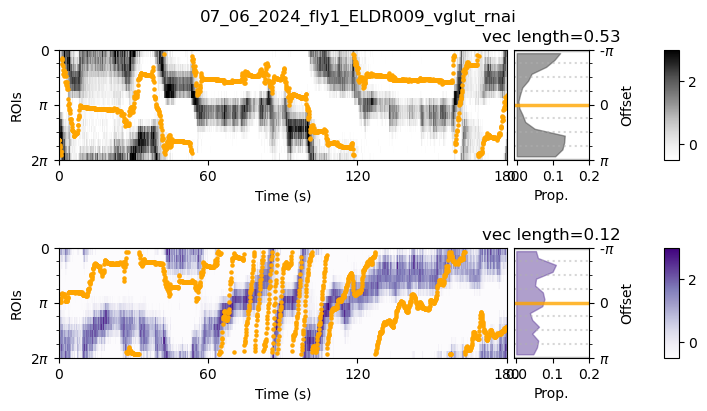

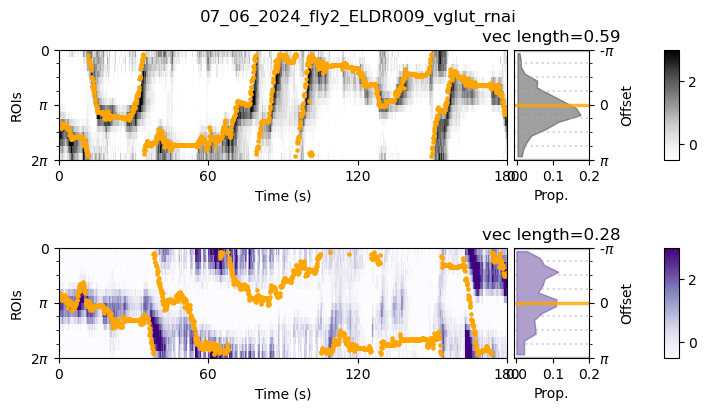

In [42]:
session_folder = figfolder / "sessions"
session_folder.mkdir(parents=True, exist_ok=True)

flies = sess_df['fly_id'].unique()
for fly in flies:
    
    cl = sess_df.loc[(sess_df['fly_id']==fly) * (sess_df['closed_loop']>1)]
    dark = sess_df.loc[(sess_df['fly_id']==fly) * (sess_df['dark']==1)]
    
    if cl.shape[0]>0 and dark.shape[0]>0:
        
        ts_dict = {'fly': fly,
                   'closed_loop': nmp.session.GetTS(load_row(cl.iloc[0])),
                   'dark': nmp.session.GetTS(load_row(dark.iloc[0])),
        }
        
        fig_heatmaps, ax_heatmas = nmp.tbh_rnai.plot_sess_heatmaps_w_hist(ts_dict, twindow=[0,180.1])
       
    
    fly_folder = session_folder / fly
    fly_folder.mkdir(parents=True, exist_ok=True)
    
    fig_heatmaps.savefig(fly_folder / "heatmaps.pdf")